# 1. Project Overview

This notebook implements the BITS Pilani AIMLCZG523 MLOps Assignment 01 using the UCI Heart Disease dataset.

The project covers the complete lifecycle:

1. Data acquisition and exploratory data analysis
2. Feature engineering and model development
3. MLflow experiment tracking
4. Model packaging and reproducibility
5. Unit testing and CI/CD
6. Docker containerization
7. Kubernetes deployment
8. API logging and monitoring
9. Documentation and submission preparation

The notebook is intentionally organized as a sequence of numbered cells so that each stage can be executed and demonstrated independently.


## 2. Install Required Python Packages


In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn ucimlrepo mlflow joblib fastapi uvicorn pydantic prometheus-client pytest httpx


Note: you may need to restart the kernel to use updated packages.


# 3. Import Libraries and Define Project Paths

This cell imports the libraries used by the data, machine learning, experiment tracking, API, and evaluation stages.

The project uses a single reusable preprocessing and model pipeline so that training-time transformations and inference-time transformations remain consistent.


## 4. Imports and Configuration


In [3]:
from pathlib import Path

RANDOM_STATE = 42

BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "data"
ARTIFACT_DIR = BASE_DIR / "artifacts"
FIGURE_DIR = ARTIFACT_DIR / "figures"
MODEL_DIR = ARTIFACT_DIR / "models"
MLRUN_DIR = BASE_DIR / "mlruns"

for directory in [
    DATA_DIR,
    ARTIFACT_DIR,
    FIGURE_DIR,
    MODEL_DIR,
    MLRUN_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

RAW_DATA_FILE = DATA_DIR / "heart_disease_raw.csv"

print("Project directory:", BASE_DIR.resolve())
print("Data directory:", DATA_DIR.resolve())
print("Artifact directory:", ARTIFACT_DIR.resolve())
print("Dataset exists:", RAW_DATA_FILE.exists())

if not RAW_DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found: {RAW_DATA_FILE}"
    )

Project directory: /home/s2025ae05507/workspace/heart_disease_mlops
Data directory: /home/s2025ae05507/workspace/heart_disease_mlops/data
Artifact directory: /home/s2025ae05507/workspace/heart_disease_mlops/artifacts
Dataset exists: True


# 5. Data Acquisition

The assignment requires the Heart Disease UCI Dataset and asks for a download script or instructions.

This project uses the UCI Machine Learning Repository dataset through the ucimlrepo Python package. The downloaded feature and target tables are combined and saved locally as a CSV file so that later stages operate on a reproducible project artifact.


## 6. Download the UCI Heart Disease Dataset


In [4]:

# Download the UCI dataset only if the CSV does not already exist

raw_csv = DATA_DIR / "heart_disease_raw.csv"

if raw_csv.exists():
    df = pd.read_csv(raw_csv)
    print("Using existing dataset:", raw_csv.resolve())
else:
    heart_disease = fetch_ucirepo(id=45)

    X_raw = heart_disease.data.features.copy()
    y_raw = heart_disease.data.targets.copy()

    df = pd.concat([X_raw, y_raw], axis=1)
    df.to_csv(raw_csv, index=False)

    print("Downloaded and saved dataset:", raw_csv.resolve())

print("Dataset shape:", df.shape)
print("Columns:")
print(df.columns.tolist())

display(df.head())


Using existing dataset: /home/s2025ae05507/workspace/heart_disease_mlops/data/heart_disease_raw.csv
Dataset shape: (303, 14)
Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


# 7. Initial Data Inspection

Before cleaning the data, inspect the dimensions, data types, missing values, and target distribution.

The UCI Heart Disease target represents the presence or absence of heart disease. For this assignment, the target is converted to a binary classification problem: 0 means absence and any positive value means presence.


## 8. Inspect the Dataset


In [5]:
print("Dataset shape:", df.shape)
display(df.head())

print("Data types:")
display(df.dtypes.to_frame("dtype"))

print("Missing values:")
display(df.isna().sum().to_frame("missing_count"))

target_column = df.columns[-1]
print("Original target column:", target_column)
print("Original target values:")
display(df[target_column].value_counts(dropna=False).sort_index())


Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


Data types:


,dtype
age,int64
sex,int64
cp,int64
trestbps,int64
chol,int64
fbs,int64
restecg,int64
thalach,int64
exang,int64
oldpeak,float64


Missing values:


,missing_count
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Original target column: num
Original target values:


num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

# 9. Clean and Prepare the Target

The original UCI target can contain multiple values representing different levels of disease. The assignment asks for a binary target, so all positive disease values are mapped to 1.

The feature values are converted to numeric where required. Missing values are retained at this stage because the machine learning preprocessing pipeline will handle them without leaking information from the test set into training.


## 10. Create the Binary Classification Dataset


In [6]:

df = df.copy()

# Convert dataset columns to numeric values
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Ensure the original target has no missing values
if df[target_column].isna().any():
    raise ValueError("The original target column contains missing values.")

# Convert the original target into binary classification
df["target"] = (df[target_column] > 0).astype(int)

# Remove the original target to prevent data leakage
if target_column != "target":
    df = df.drop(columns=[target_column])

print("Cleaned dataset shape:", df.shape)
print("\nTarget distribution:")
display(df["target"].value_counts().sort_index())

print("\nMissing values after cleaning:")
display(df.isna().sum().to_frame("missing_count"))

# Save the cleaned dataset
clean_csv = DATA_DIR / "heart_disease_clean.csv"
df.to_csv(clean_csv, index=False)

print("\nSaved:", clean_csv.resolve())


Cleaned dataset shape: (303, 14)

Target distribution:


target
0    164
1    139
Name: count, dtype: int64


Missing values after cleaning:


,missing_count
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0



Saved: /home/s2025ae05507/workspace/heart_disease_mlops/data/heart_disease_clean.csv


# 11. Exploratory Data Analysis

This section creates the professional visualizations requested in the assignment.

The analysis includes:

- Dataset summary statistics
- Class balance
- Histograms for numerical variables
- Correlation heatmap

The figures are saved under the artifacts/figures directory so that they can later be logged to MLflow and included in the final report.


## 12. Summary Statistics


In [7]:
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## 13. Class Balance Visualization


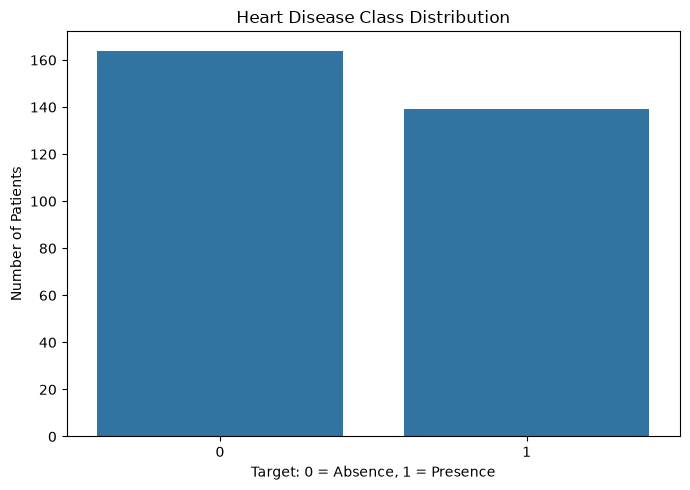

Saved: /home/s2025ae05507/workspace/heart_disease_mlops/artifacts/figures/class_balance.png


In [8]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="target")
plt.title("Heart Disease Class Distribution")
plt.xlabel("Target: 0 = Absence, 1 = Presence")
plt.ylabel("Number of Patients")
plt.tight_layout()

class_balance_path = FIGURE_DIR / "class_balance.png"
plt.savefig(class_balance_path, dpi=200)
plt.show()

print("Saved:", class_balance_path.resolve())


## 14. Numerical Feature Histograms


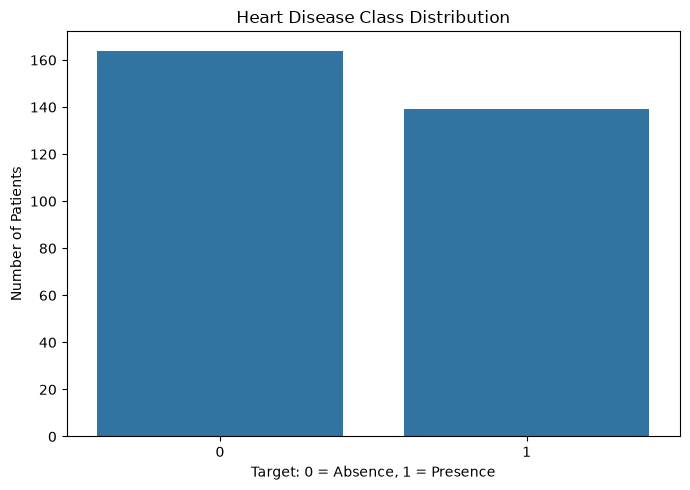

Saved: /home/s2025ae05507/workspace/heart_disease_mlops/artifacts/figures/class_balance.png


In [ ]:
# Numerical Feature Histograms
numerical_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    values = pd.to_numeric(df[feature], errors="coerce").dropna()
    axes[i].hist(values, bins=15, edgecolor="black")
    axes[i].set_title(feature)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Frequency")
    axes[i].grid(axis="y", alpha=0.25)

axes[5].axis("off")
fig.suptitle("Heart Disease Dataset: Numerical Feature Distributions")
fig.tight_layout()

histogram_path = FIGURE_DIR / "numerical_feature_histograms.png"
fig.savefig(histogram_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", histogram_path.resolve())

## 15. Correlation Heatmap


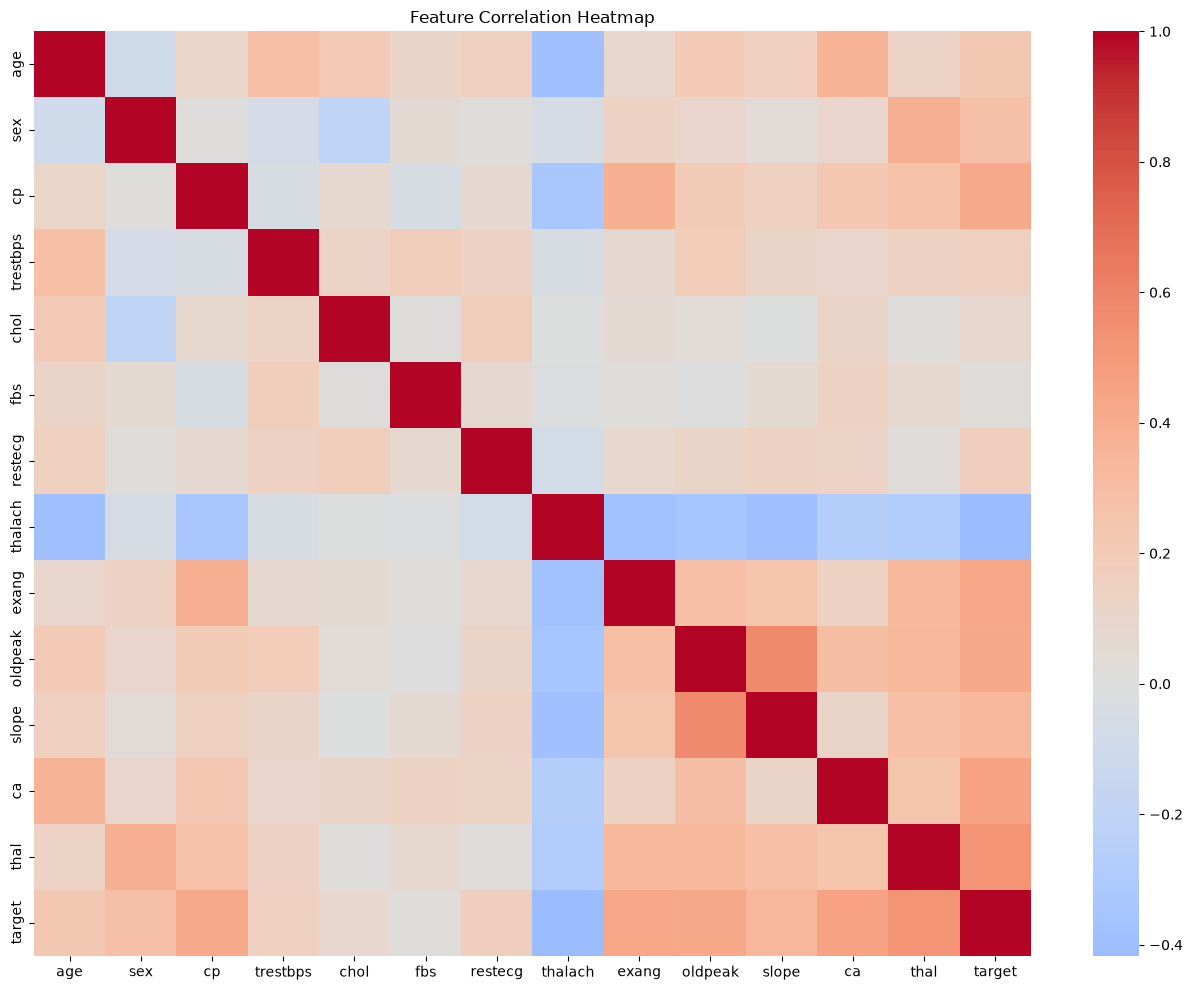

Saved: /home/s2025ae05507/workspace/heart_disease_mlops/artifacts/figures/correlation_heatmap.png


In [10]:
plt.figure(figsize=(13, 10))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()

heatmap_path = FIGURE_DIR / "correlation_heatmap.png"
plt.savefig(heatmap_path, dpi=200)
plt.show()

print("Saved:", heatmap_path.resolve())


# 16. Feature Engineering and Train-Test Split

The model input consists of all features except target.

The data is split using stratification so that the training and test sets retain a similar class distribution.

The preprocessing pipeline separates numerical and categorical features. Numerical features are median-imputed and standardized. Categorical features are median-imputed and one-hot encoded.

Keeping preprocessing inside the pipeline is important for reproducibility and prevents inconsistent transformations during API inference.


## 17. Prepare Features and Split the Data


In [11]:

# Separate input features and target
X = df.drop(columns=["target"])
y = df["target"]

# Identify categorical and numerical features
categorical_features = [
    "sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"
]

numerical_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

# Keep only features that exist in X
categorical_features = [c for c in categorical_features if c in X.columns]
numerical_features = [c for c in numerical_features if c in X.columns]

# Split the dataset while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

print("\nTraining target distribution:")
display(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
display(y_test.value_counts().sort_index())

print("\nTarget leakage check:", "target" not in X_train.columns)


Training rows: 242
Testing rows: 61
Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
Numerical features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Training target distribution:


target
0    131
1    111
Name: count, dtype: int64


Testing target distribution:


target
0    33
1    28
Name: count, dtype: int64


Target leakage check: True


## 18. Create the Reusable Preprocessing Pipeline


In [12]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print(preprocessor)


ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'trestbps', 'chol', 'thalach',
                                  'oldpeak']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['sex', 'cp', 'fbs', 'restecg', 'exang',
                                  'slope', 'ca', 'thal'])])


# 19. Model Development

Two classification models are developed as required by the assignment:

1. Logistic Regression
2. Random Forest

Both models use the same preprocessing pipeline. This makes their evaluation comparable and ensures that the exact same feature preparation is used for each experiment.


## 20. Create the Two Model Pipelines


In [13]:
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]
)

random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            class_weight="balanced"
        ))
    ]
)

models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": random_forest_pipeline
}

print("Models prepared:", list(models.keys()))


Models prepared: ['Logistic Regression', 'Random Forest']


# 21. Cross-Validation Evaluation

Cross-validation is used to estimate model performance more reliably than relying on a single split.

The requested metrics are:

- Accuracy
- Precision
- Recall
- ROC-AUC

The mean and standard deviation across the folds are recorded for comparison.


## 22. Evaluate Both Models with Cross-Validation


In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc"
}

cv_results = []

for model_name, pipeline in models.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    result = {
        "model": model_name,
        "accuracy_mean": scores["test_accuracy"].mean(),
        "accuracy_std": scores["test_accuracy"].std(),
        "precision_mean": scores["test_precision"].mean(),
        "recall_mean": scores["test_recall"].mean(),
        "roc_auc_mean": scores["test_roc_auc"].mean()
    }

    cv_results.append(result)

cv_results_df = pd.DataFrame(cv_results).sort_values(
    "roc_auc_mean", ascending=False
)

display(cv_results_df)
cv_results_df.to_csv(ARTIFACT_DIR / "cross_validation_results.csv", index=False)


,model,accuracy_mean,accuracy_std,precision_mean,recall_mean,roc_auc_mean
0,Logistic Regression,0.847109,0.009977,0.876753,0.783399,0.902493
1,Random Forest,0.801616,0.021454,0.778838,0.800791,0.898511


# 23. Model Selection and Tuning

The model with the strongest cross-validation ROC-AUC is selected as the candidate model.

A small hyperparameter search is then performed for the Random Forest model. The search is intentionally limited so that it remains practical in a constrained BITS virtual lab.

The final model is selected based on cross-validation ROC-AUC.


## 24. Tune Random Forest


In [15]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            random_state=RANDOM_STATE,
            class_weight="balanced"
        ))
    ]
)

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    rf_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)
print("Best cross-validation ROC-AUC:", grid_search.best_score_)


Best parameters:
{'model__max_depth': 5, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best cross-validation ROC-AUC: 0.9017122169296081


# 25. Final Model Evaluation

The tuned Random Forest is evaluated on the untouched test set.

This test-set evaluation is used as the final model performance estimate because the test data was not used during model selection.


## 26. Evaluate the Final Model


In [16]:

final_model = grid_search.best_estimator_

# Train the best model on the full training set
final_model.fit(X_train, y_train)

# Predict the test set
test_predictions = final_model.predict(X_test)
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
final_metrics = {
    "accuracy": accuracy_score(y_test, test_predictions),
    "precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test, test_probabilities)
}

print("Final Test Metrics")
for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report")
print(classification_report(
    y_test, test_predictions, zero_division=0
))


Final Test Metrics
accuracy: 0.8852
precision: 0.8387
recall: 0.9286
roc_auc: 0.9513

Classification Report
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



## 27. Confusion Matrix and ROC Curve


In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    ax=ax
)
ax.set_title("Final Model Confusion Matrix")
plt.tight_layout()

confusion_path = FIGURE_DIR / "confusion_matrix.png"
plt.savefig(confusion_path, dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities,
    ax=ax
)
ax.set_title("Final Model ROC Curve")
plt.tight_layout()

roc_path = FIGURE_DIR / "roc_curve.png"
plt.savefig(roc_path, dpi=200)
plt.show()

print("Saved:", confusion_path.resolve())
print("Saved:", roc_path.resolve())


# 28. MLflow Experiment Tracking

MLflow is used to record experiment parameters, metrics, and artifacts.

A local MLflow tracking directory is used so that the project can run in the BITS lab without requiring an external MLflow server.

The experiment records the model configuration, cross-validation metrics, final test metrics, plots, and the trained model.


## 29. Configure MLflow


In [18]:

# Configure MLflow to use a local SQLite tracking database
MLFLOW_DB = BASE_DIR / "mlflow.db"
mlflow_tracking_uri = f"sqlite:///{MLFLOW_DB}"

mlflow.set_tracking_uri(mlflow_tracking_uri)

experiment_name = "heart-disease-classification"
experiment = mlflow.get_experiment_by_name(experiment_name)

if experiment is None:
    experiment_id = mlflow.create_experiment(experiment_name)
else:
    experiment_id = experiment.experiment_id

mlflow.set_experiment(experiment_name)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("Experiment name:", experiment_name)
print("Experiment ID:", experiment_id)
print("MLflow setup completed successfully.")


2026/10/13 12:27:09 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/13 12:27:10 INFO mlflow.store.db.utils: Updating database tables


MLflow tracking URI: sqlite:////home/s2025ae05507/workspace/heart_disease_mlops/mlflow.db
Experiment name: heart-disease-classification
Experiment ID: 1
MLflow setup completed successfully.


## 30. Log the Final Experiment to MLflow


In [20]:

with mlflow.start_run(run_name="random-forest-final"):
    # Log model parameters
    mlflow.log_params(grid_search.best_params_)

    # Log evaluation metrics
    mlflow.log_metrics({
        "cv_best_roc_auc": float(grid_search.best_score_),
        "test_accuracy": float(final_metrics["accuracy"]),
        "test_precision": float(final_metrics["precision"]),
        "test_recall": float(final_metrics["recall"]),
        "test_roc_auc": float(final_metrics["roc_auc"])
    })

    # Log generated charts
    for figure_path in FIGURE_DIR.glob("*.png"):
        mlflow.log_artifact(
            str(figure_path),
            artifact_path="figures"
        )

    # Log cross-validation results
    mlflow.log_artifact(
        str(ARTIFACT_DIR / "cross_validation_results.csv")
    )

    # Log the trained model
    mlflow.sklearn.log_model(
        sk_model=final_model,
        name="model",
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.tree._tree.Tree"
        ]
    )

    print("MLflow run ID:", mlflow.active_run().info.run_id)


MLflow run ID: 601aa271de0045f79a7a6f135e7e3300


# 31. Save the Reproducible Model

The complete preprocessing and model pipeline is saved as one artifact.

This is important because the API must perform exactly the same preprocessing that was used during training.

The model is stored with joblib and can be loaded later without retraining.


## 32. Save Model and Metadata


In [21]:
model_path = MODEL_DIR / "heart_disease_model.joblib"
joblib.dump(final_model, model_path)

metadata = {
    "problem": "Binary classification of heart disease presence",
    "dataset": "UCI Heart Disease Dataset",
    "model": "Random Forest",
    "random_state": RANDOM_STATE,
    "features": X.columns.tolist(),
    "categorical_features": categorical_features,
    "numerical_features": numerical_features,
    "metrics": final_metrics,
    "best_parameters": grid_search.best_params_
}

metadata_path = ARTIFACT_DIR / "model_metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2))

print("Model saved:", model_path.resolve())
print("Metadata saved:", metadata_path.resolve())


Model saved: /home/s2025ae05507/workspace/heart_disease_mlops/artifacts/models/heart_disease_model.joblib
Metadata saved: /home/s2025ae05507/workspace/heart_disease_mlops/artifacts/model_metadata.json


# 33. Test Model Reload and Inference

A reproducibility check loads the saved model from disk and performs inference on a test sample.

This confirms that the model artifact can be used independently after training.


## 34. Reload the Saved Model


In [22]:
loaded_model = joblib.load(model_path)

sample_input = X_test.iloc[[0]]
sample_prediction = int(loaded_model.predict(sample_input)[0])
sample_confidence = float(loaded_model.predict_proba(sample_input)[0].max())

print("Sample input:")
display(sample_input)

print("Prediction:", sample_prediction)
print("Confidence:", round(sample_confidence, 4))


Sample input:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
219,59,1,4,138,271,0,2,182,0,0.0,1,0.0,3.0


Prediction: 0
Confidence: 0.7196


# 35. Generate Requirements File

The requirements file records the Python dependencies needed to reproduce the project.

The exact versions printed below can be copied into requirements.txt for the repository.


## 36. Create requirements.txt


In [23]:
requirements = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "ucimlrepo",
    "mlflow",
    "joblib",
    "fastapi",
    "uvicorn",
    "pydantic",
    "prometheus-client",
    "pytest",
    "httpx"
]

requirements_path = BASE_DIR / "requirements.txt"
requirements_path.write_text("\n".join(requirements) + "\n")

print(requirements_path.read_text())


pandas
numpy
matplotlib
seaborn
scikit-learn
ucimlrepo
mlflow
joblib
fastapi
uvicorn
pydantic
prometheus-client
pytest
httpx



# 37. Unit Testing

The assignment requires unit tests for data processing and model code.

The project includes tests for:

- Dataset structure
- Model artifact loading
- Prediction output
- Prediction confidence

The tests are intentionally small and deterministic so that they can run in CI/CD.


# 38. Prepare a Sample for the API

The API accepts the original feature names as JSON fields.

The saved model pipeline performs all preprocessing internally, so the API does not need to duplicate preprocessing logic.


## 39. Display the Expected API Input Schema


In [24]:

print("API input fields:")
print(X.columns.tolist())

print("\nExample input:")
print(X_test.iloc[0].to_dict())


API input fields:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Example input:
{'age': 59.0, 'sex': 1.0, 'cp': 4.0, 'trestbps': 138.0, 'chol': 271.0, 'fbs': 0.0, 'restecg': 2.0, 'thalach': 182.0, 'exang': 0.0, 'oldpeak': 0.0, 'slope': 1.0, 'ca': 0.0, 'thal': 3.0}


# 40. FastAPI and Production Serving

The production API is implemented in src/api.py.

The API exposes:

- GET /health for health checking
- POST /predict for model inference
- GET /metrics for Prometheus-compatible metrics

The API also logs request information such as method, endpoint, status code, and processing time.


# 41. Docker Container

The Dockerfile packages the FastAPI service, Python dependencies, and saved model into an isolated runtime environment.

The container is designed to expose port 8000 and run the FastAPI application with Uvicorn.


# 42. CI/CD Workflow

GitHub Actions is used to automatically:

1. Install dependencies
2. Run unit tests
3. Build the Docker image

The workflow is configured to fail when the tests fail.


# 43. Kubernetes Deployment

The Kubernetes manifests provide a simple production-style deployment.

The deployment runs the container and the service exposes port 8000 inside the Kubernetes environment.

For the BITS lab, Minikube is the recommended starting point if Kubernetes is available.


# 44. Monitoring and Logging

The API includes basic request logging and Prometheus-compatible metrics.

This satisfies the assignment requirement for API request logging and simple monitoring. Grafana can be added later if the BITS environment has sufficient resources.


# 45. Final Verification Checklist

Before submission, verify each assignment requirement.

Data and EDA:
- UCI dataset downloaded
- Data cleaning completed
- Missing values handled
- Histograms created
- Correlation heatmap created
- Class balance visualization created

Model development:
- Logistic Regression evaluated
- Random Forest evaluated
- Cross-validation completed
- Accuracy, precision, recall, ROC-AUC recorded
- Final model selected and tuned

Experiment tracking:
- MLflow experiment created
- Parameters logged
- Metrics logged
- Figures logged
- Model logged

Reproducibility:
- Model saved
- Preprocessing included in the pipeline
- requirements.txt created

CI/CD:
- Unit tests created
- GitHub Actions workflow created
- Test failure stops the workflow

Containerization:
- Dockerfile created
- Image builds successfully
- Container starts
- /predict works

Deployment:
- Kubernetes manifest created
- Deployment starts
- Service is reachable
- Deployment screenshot captured

Monitoring:
- API request logs visible
- /metrics endpoint available

Documentation:
- README completed
- Architecture diagram added
- Screenshots collected
- 10-page report prepared
- Short pipeline video recorded


# 46. Conclusion

The completed project demonstrates an end-to-end MLOps lifecycle for a binary heart disease classification problem.

The final flow is:

Data acquisition
to EDA
to feature engineering
to model training
to experiment tracking
to reproducible packaging
to automated testing
to CI/CD
to Docker
to Kubernetes deployment
to API monitoring.

The notebook should be used as the main execution and demonstration guide, while the supporting source files form the GitHub repository deliverable.
